# Iris Flower Classification
### EDA, feature selection, and model comparison

**Goal.** Classify iris flowers as Setosa, Versicolor, or Virginica from four measurements. This notebook loads scikit-learn?s built-in dataset, explores its structure, compares two classifiers on a stratified holdout set, and evaluates the selected model. The dataset is small and clean, so the test score should be interpreted alongside the confusion matrix and cross-validation rather than as a universal performance guarantee.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams['figure.figsize'] = (9, 5)

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.rename(columns={c: c.replace(' (cm)','') for c in iris.feature_names})
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
features = [c for c in df.columns if c not in ['target','species']]
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())
print('Data types:'); print(df.dtypes)
print('Missing values:'); print(df.isna().sum())
display(df[features].describe().T)
print('Class counts:'); print(df['species'].value_counts())

Rows: 150 | Columns: 6


,sepal length,sepal width,petal length,petal width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Data types:
sepal length    float64
sepal width     float64
petal length    float64
petal width     float64
target            int64
species             str
dtype: object
Missing values:
sepal length    0
sepal width     0
petal length    0
petal width     0
target          0
species         0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
sepal length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


Class counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


The built-in dataset contains 150 observations, four numeric measurements, and three balanced species classes. Confirm the printed missing-value and class-count tables before modeling; balanced classes make accuracy reasonably interpretable here.

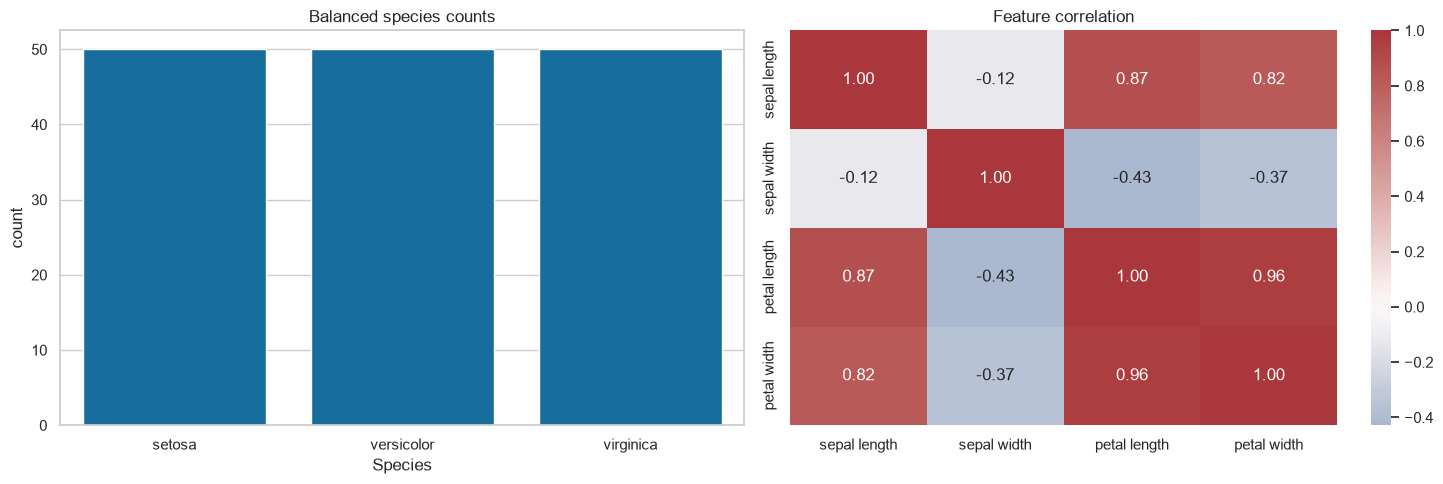

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x='species', order=iris.target_names, ax=ax[0])
ax[0].set_title('Balanced species counts'); ax[0].set_xlabel('Species')
sns.heatmap(df[features].corr(), annot=True, cmap='vlag', center=0, fmt='.2f', ax=ax[1])
ax[1].set_title('Feature correlation')
plt.tight_layout(); plt.show()

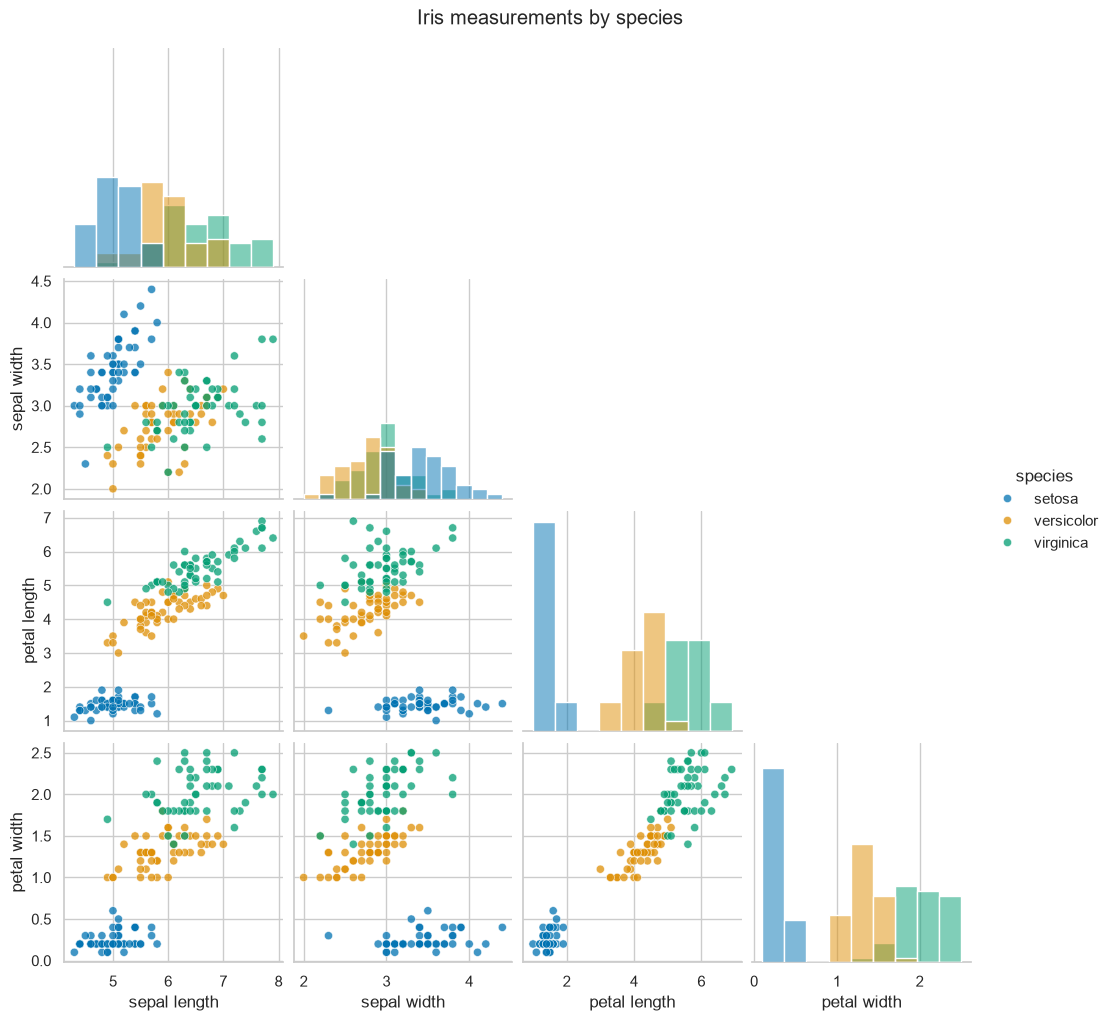

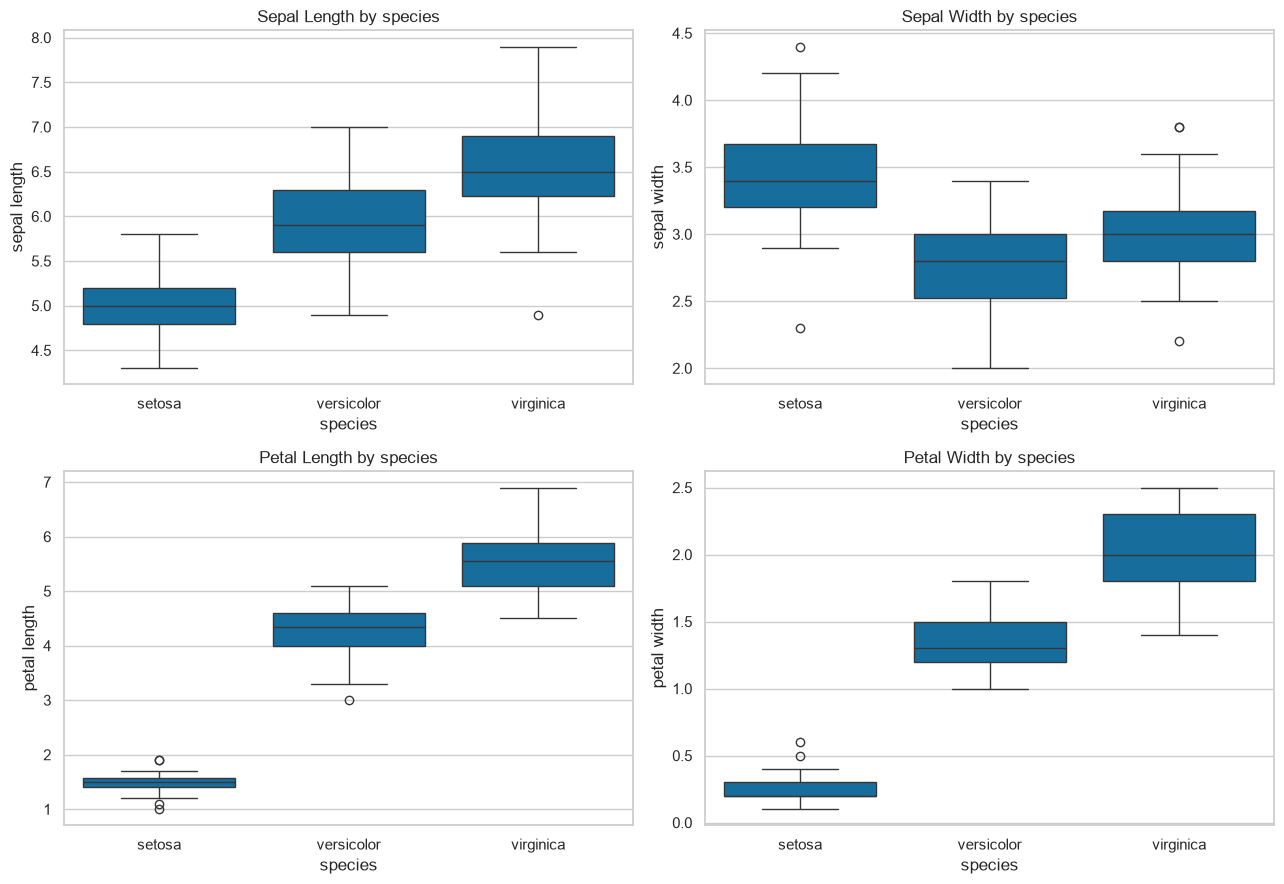

In [4]:
g = sns.pairplot(df, vars=features, hue='species', corner=True, diag_kind='hist', plot_kws={'alpha':.75,'s':35})
g.fig.suptitle('Iris measurements by species', y=1.02); plt.show()
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for feature, ax in zip(features, axes.flat):
    sns.boxplot(data=df, x='species', y=feature, order=iris.target_names, ax=ax)
    ax.set_title(f'{feature.title()} by species')
plt.tight_layout(); plt.show()

**Feature selection reading:** inspect the pairplot and boxplots for separation and overlap, then use the group means below as a compact check. Petal length and petal width usually separate Setosa clearly and help distinguish the other two species; sepal measurements overlap more. Correlated measurements also carry partly redundant information, so visual separation is more useful here than treating correlations as independent effects.

In [5]:
display(df.groupby('species')[features].mean().round(2))

,sepal length,sepal width,petal length,petal width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


In [6]:
X, y = df[features], df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'K-Nearest Neighbours (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
}
rows, fitted = [], {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    model.fit(X_train, y_train); fitted[name] = model
    pred = model.predict(X_test)
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    rows.append({'Model':name,'Test accuracy':accuracy_score(y_test,pred),'Train CV mean':cv_scores.mean(),'Train CV SD':cv_scores.std()})
results = pd.DataFrame(rows).sort_values('Test accuracy',ascending=False)
display(results.round(3))
best_name = results.iloc[0]['Model']; best_model = fitted[best_name]
print(f'Best by holdout accuracy: {best_name}. Cross-validation is shown as a stability check; with only 30 test flowers, a single test score is noisy.')

,Model,Test accuracy,Train CV mean,Train CV SD
0,Logistic Regression,0.933,0.958,0.026
1,K-Nearest Neighbours (k=5),0.933,0.958,0.026


Best by holdout accuracy: Logistic Regression. Cross-validation is shown as a stability check; with only 30 test flowers, a single test score is noisy.


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



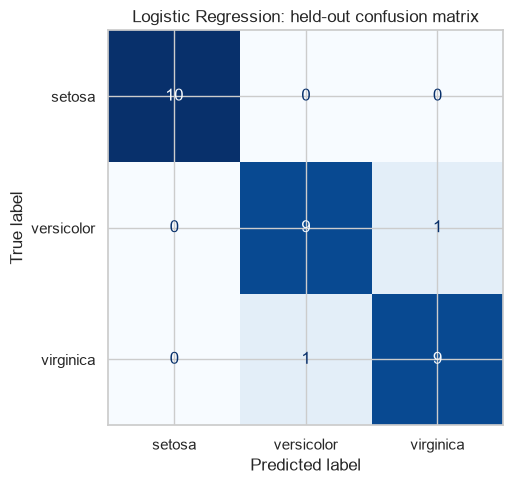

In [7]:
best_pred = best_model.predict(X_test)
print(classification_report(y_test, best_pred, target_names=iris.target_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=iris.target_names, cmap='Blues', colorbar=False)
plt.title(f'{best_name}: held-out confusion matrix'); plt.tight_layout(); plt.show()

## Conclusion
The comparison table identifies the best observed holdout model; the report and confusion matrix show which species, if any, are confused. The selected model is justified by its held-out accuracy together with its cross-validation mean and class-level precision/recall. Because the data are tiny, small score differences should not be treated as conclusive evidence that one classifier is always better.